<a href="https://colab.research.google.com/github/ulugbek-lab/VisualSortAi/blob/main/VisualSortAi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
# ------------------------------
# Import Libraries
# ------------------------------


from google.colab import drive
import torchvision.transforms as transforms
from torch.utils.data import Dataset
from PIL import Image, UnidentifiedImageError
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import mobilenet_v2
import os
import numpy as np


In [20]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
DATASET_PATH = "/content/drive/MyDrive/waste_dataset"

CUSTOM_CLASS_MAPPING = {
    "glass": "glass",
    "plastic": "plastic",

    "clothes": "textile",
    "shoes": "textile",

    "organic": "organic",

    "paper-cardboard": "paper-cardboard",
    "paper": "paper-cardboard",

    "metal": "metal"
}

CLASSES = [
    "paper-cardboard",
    "glass",
    "metal",
    "plastic",
    "organic",
    "textile"
]

CLASS_TO_IDX = {
    cls: i for i, cls in enumerate(CLASSES)
}

NUM_CLASSES = len(CLASSES)

print(CLASS_TO_IDX)
print("Number of classes:", NUM_CLASSES)

{'paper-cardboard': 0, 'glass': 1, 'metal': 2, 'plastic': 3, 'organic': 4, 'textile': 5}
Number of classes: 6


In [23]:


all_images = []

SUBFOLDERS = ["default", "real_world"]

for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():

    class_path = os.path.join(DATASET_PATH, original_class)

    print(f"\nReading: {original_class} -> {mapped_class}")

    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue

    for subfolder in SUBFOLDERS:

        subfolder_path = os.path.join(class_path, subfolder)

        if not os.path.exists(subfolder_path):
            print(f"Warning: {subfolder_path} not found")
            continue

        for img_name in os.listdir(subfolder_path):

            if img_name.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):

                full_path = os.path.join(
                    subfolder_path,
                    img_name
                )

                label = CLASS_TO_IDX[mapped_class]

                all_images.append(
                    (full_path, label)
                )

print("\nTotal images:", len(all_images))


Reading: glass -> glass

Reading: plastic -> plastic

Reading: clothes -> textile

Reading: shoes -> textile

Reading: organic -> organic

Reading: paper-cardboard -> paper-cardboard

Reading: paper -> paper-cardboard

Reading: metal -> metal

Total images: 4000


In [24]:
class_counts = {cls: 0 for cls in CLASSES}

for path, label in all_images:
    class_name = CLASSES[label]
    class_counts[class_name] += 1

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

paper-cardboard: 1000
glass: 500
metal: 500
plastic: 500
organic: 500
textile: 1000


In [25]:
# ------------------------------
# Shuffle and Split
# ------------------------------

np.random.shuffle(all_images)

split = int(0.8 * len(all_images))

train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 3200
Validation images: 800


In [26]:

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [27]:
# ------------------------------
# Custom Dataset class
# ------------------------------

class WasteDataset(Dataset):

    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_path = self.images[idx]
        label = self.labels[idx]

        try:
            image = Image.open(img_path).convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))

        if self.transform:
            image = self.transform(image)

        return image, label

In [28]:
train_dataset = WasteDataset(
    train_images,
    train_labels,
    transform=transform
)

val_dataset = WasteDataset(
    val_images,
    val_labels,
    transform=transform
)

In [29]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [30]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([2, 2, 5, 4, 4, 4, 1, 5, 2, 5])


In [31]:
# ------------------------------
# Device
# ------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [32]:
# ------------------------------
# Pretrained MobileNetV2
# ------------------------------

model = mobilenet_v2(weights="IMAGENET1K_V1")

In [33]:
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

In [34]:
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
torch.backends.cudnn.benchmark = True

In [36]:
NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):

    # ------------------------------
    # Training
    # ------------------------------
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    # ------------------------------
    # Validation
    # ------------------------------
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    val_accuracy = 100 * correct / total
    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Loss: {avg_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    # ------------------------------
    # Save best model
    # ------------------------------
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/content/visualsort_ai.pth"
        )

        print("✅ Saved new best VisualSort AI model!")

KeyboardInterrupt: 

# MODEL Usage

Upload one or more waste images:


Saving organic_waste.png to organic_waste.png


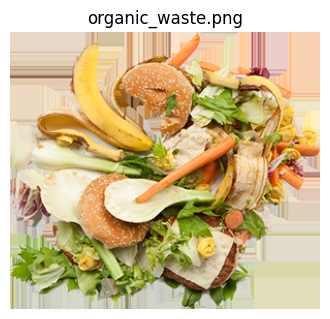

Prediction:
organic: 99.03%
textile: 0.96%
paper-cardboard: 0.01%
plastic: 0.00%
glass: 0.00%
metal: 0.00%


In [46]:
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

CLASSES = [
    "paper-cardboard",
    "glass",
    "metal",
    "plastic",
    "organic",
    "textile"
]

NUM_CLASSES = len(CLASSES)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

model = mobilenet_v2(weights=None)

model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

model.load_state_dict(
    torch.load(
        "/content/visualsort_ai.pth",
        map_location="cpu"
    )
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Upload one or more waste images:")
uploaded = files.upload()

for image_name in uploaded.keys():

    image = Image.open(
        io.BytesIO(uploaded[image_name])
    ).convert("RGB")

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(image_name)
    plt.show()

    image_tensor = (
        transform(image)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():

        output = model(image_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )[0]

        topk = torch.topk(
            probabilities,
            k=6
        )

    print("Prediction:")

    for i in range(topk.indices.size(0)):

        class_index = topk.indices[i].item()
        label = CLASSES[class_index]

        confidence = (
            topk.values[i].item() * 100
        )

        print(
            f"{label}: {confidence:.2f}%"
        )